In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Library

In [2]:
import pandas as pd
import numpy as np


## 2. Load Dataset

In [3]:
df = pd.read_csv("/content/drive/MyDrive/Dataset2.csv")
df.head()

,timestamp,indoor_temp_c,indoor_humidity_pct,outdoor_temp_c,outdoor_humidity_pct,day_period,ac_setpoint_c
0,2026-10-15 08:00:00,26.44,69.06,26.22,77.71,Morning,24.5
1,2026-10-15 08:05:00,26.52,69.72,26.19,76.87,Morning,24.5
2,2026-10-15 08:10:00,26.53,69.89,26.35,76.03,Morning,24.5
3,2026-10-15 08:15:00,26.50,70.07,26.31,74.33,Morning,24.5
4,2026-10-15 08:20:00,26.51,70.16,26.36,72.59,Morning,24.5


## 3. Explore Dataset

In [4]:
# Dataset information
print("Dataset Shape:", df.shape)
print("=========================")

# Column information
print("\nDataset Information:")
df.info()
print("=========================")

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())
print("=========================")

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())
print("=========================")

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (1635, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1635 entries, 0 to 1634
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   timestamp             1635 non-null   object 
 1   indoor_temp_c         1635 non-null   float64
 2   indoor_humidity_pct   1635 non-null   float64
 3   outdoor_temp_c        1635 non-null   float64
 4   outdoor_humidity_pct  1635 non-null   float64
 5   day_period            1635 non-null   object 
 6   ac_setpoint_c         1635 non-null   float64
dtypes: float64(5), object(2)
memory usage: 89.5+ KB

Missing Values:
timestamp               0
indoor_temp_c           0
indoor_humidity_pct     0
outdoor_temp_c          0
outdoor_humidity_pct    0
day_period              0
ac_setpoint_c           0
dtype: int64

Statistical Summary:


,indoor_temp_c,indoor_humidity_pct,outdoor_temp_c,outdoor_humidity_pct,ac_setpoint_c
count,1635.000000,1635.000000,1635.000000,1635.000000,1635.000000
mean,24.621254,64.088000,27.586153,67.251878,23.662691
std,1.143053,12.857459,0.917810,9.444261,1.333984
min,21.590000,40.780000,24.850000,46.010000,20.500000
25%,23.800000,54.960000,26.990000,60.120000,23.000000
50%,24.790000,62.820000,27.590000,68.170000,23.500000
75%,25.460000,73.715000,28.200000,74.815000,24.500000
max,26.970000,90.000000,29.970000,89.210000,27.000000



Duplicate Rows: 0


## 4. Preprocess the data

In [5]:
# Convert timestamp into datetime
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Extract hour and minute
df["hour"] = df["timestamp"].dt.hour
df["minute"] = df["timestamp"].dt.minute

# Convert day_period into numerical values
df["day_period"] = df["day_period"].map({
    "Morning": 0,
    "Afternoon": 1,
    "Evening": 2
})

# Drop original timestamp
df = df.drop(columns=["timestamp"])

# Check processed data
df.head()

,indoor_temp_c,indoor_humidity_pct,outdoor_temp_c,outdoor_humidity_pct,day_period,ac_setpoint_c,hour,minute
0,26.44,69.06,26.22,77.71,0,24.5,8,0
1,26.52,69.72,26.19,76.87,0,24.5,8,5
2,26.53,69.89,26.35,76.03,0,24.5,8,10
3,26.50,70.07,26.31,74.33,0,24.5,8,15
4,26.51,70.16,26.36,72.59,0,24.5,8,20


## 5. Select input features (X) and target (Y)

In [6]:
# Input features
X = df[
    [
        "indoor_temp_c",
        "indoor_humidity_pct",
        "outdoor_temp_c",
        "outdoor_humidity_pct",
        "day_period",
        "hour",
        "minute"
    ]
]

# Target variable
y = df["ac_setpoint_c"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Input features:
   indoor_temp_c  indoor_humidity_pct  outdoor_temp_c  outdoor_humidity_pct  \
0          26.44                69.06           26.22                 77.71   
1          26.52                69.72           26.19                 76.87   
2          26.53                69.89           26.35                 76.03   
3          26.50                70.07           26.31                 74.33   
4          26.51                70.16           26.36                 72.59   

   day_period  hour  minute  
0           0     8       0  
1           0     8       5  
2           0     8      10  
3           0     8      15  
4           0     8      20  

Target values:
0    24.5
1    24.5
2    24.5
3    24.5
4    24.5
Name: ac_setpoint_c, dtype: float64


## 6. Split + Train + Predict + Evaluation

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Random 80:20 split (diagnostic comparison only)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train model
random_model = LinearRegression()
random_model.fit(X_train_r, y_train_r)

# Predict
random_pred = random_model.predict(X_test_r)

# Evaluate
print("Random Split Performance")
print("MAE:", mean_absolute_error(y_test_r, random_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test_r, random_pred)))
print("R2:", r2_score(y_test_r, random_pred))

Random Split Performance
MAE: 0.8613613041792103
RMSE: 1.0856854945832173
R2: 0.3715399703100408


Slope of each Feature

In [8]:
# Display slope (coefficient) of each feature

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Slope": random_model.coef_
})

print("Linear Regression Slopes:")
display(coefficients)

print("Intercept:", random_model.intercept_)

Linear Regression Slopes:


,Feature,Slope
0,indoor_temp_c,0.011553
1,indoor_humidity_pct,-0.018828
2,outdoor_temp_c,-0.426099
3,outdoor_humidity_pct,-0.025594
4,day_period,0.842747
5,hour,-0.356397
6,minute,-0.001712


Intercept: 41.83282559210716


Straight Line

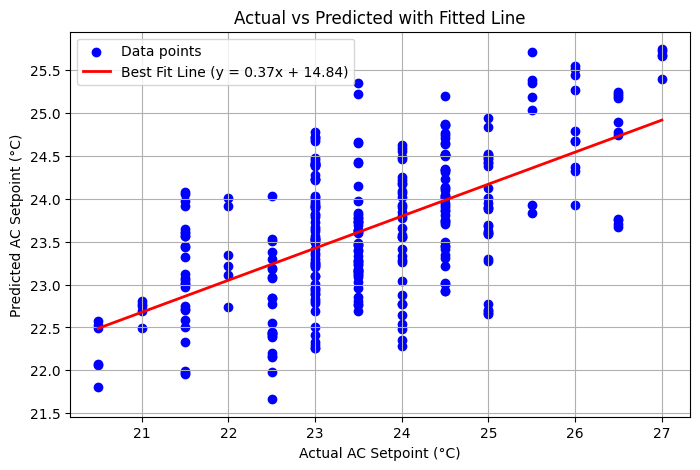

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate the slope (m) and y-intercept (c) of the regression line of best fit
m, c = np.polyfit(y_test_r, random_pred, 1)

plt.figure(figsize=(8, 5))

# Plot scatter points of actual vs predicted values
plt.scatter(y_test_r, random_pred, color='blue', label='Data points')

# Generate points for the regression line
x_line = np.linspace(min(y_test_r), max(y_test_r), 100)
y_line = m * x_line + c

# Plot the regression line (y = mx + c)
plt.plot(x_line, y_line, color='red', linewidth=2, label=f'Best Fit Line (y = {m:.2f}x + {c:.2f})')

plt.xlabel("Actual AC Setpoint (°C)")
plt.ylabel("Predicted AC Setpoint (°C)")
plt.title("Actual vs Predicted with Fitted Line")
plt.grid(True)
plt.legend()
plt.show()

## 7. Plot Actual vs Preidcted

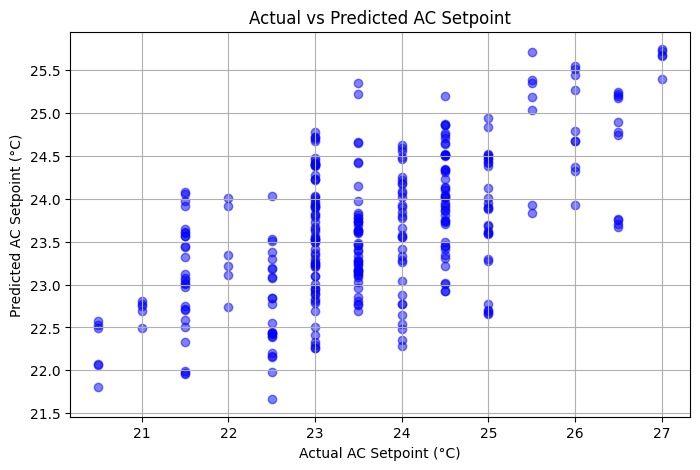

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Using the correct split variable names
plt.scatter(y_test_r, random_pred, alpha=0.5, color='blue')

plt.xlabel("Actual AC Setpoint (°C)")
plt.ylabel("Predicted AC Setpoint (°C)")
plt.title("Actual vs Predicted AC Setpoint")
plt.grid(True)
plt.show()

## 8. Download Trained Model

In [11]:
import joblib

# Save the correct trained model variable
joblib.dump(random_model, "classroom_ac_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [12]:
#@title Predict AC Setpoint from User Input
import pandas as pd
import numpy as np

# User Inputs via Colab Forms
indoor_temp_c = 24 #@param {type:"number"}
indoor_humidity_pct = 54 #@param {type:"number"}
outdoor_temp_c = 26.6 #@param {type:"number"}
outdoor_humidity_pct = 88 #@param {type:"number"}
day_period = "Morning" #@param ["Morning", "Afternoon", "Evening"]
time = "08:47" #@param {type:"string"}

try:
    # 1. Preprocess the time input into Hour and Minute
    hour, minute = map(int, time.split(":"))

    # 2. Map day_period to numerical value
    day_period_map = {"Morning": 0, "Afternoon": 1, "Evening": 2}
    day_period_encoded = day_period_map[day_period]

    # 3. Create a DataFrame representing the single input vector
    input_data = pd.DataFrame([{
        "indoor_temp_c": indoor_temp_c,
        "indoor_humidity_pct": indoor_humidity_pct,
        "outdoor_temp_c": outdoor_temp_c,
        "outdoor_humidity_pct": outdoor_humidity_pct,
        "day_period": day_period_encoded,
        "hour": hour,
        "minute": minute
    }])

    # 4. Use the trained model to predict
    prediction = random_model.predict(input_data)[0]

    print("\n--- Preprocessed Features --- ")
    display(input_data)

    print(f"\nPredicted AC Setpoint: {prediction:.2f} °C")

except Exception as e:
    print(f"An error occurred with your inputs. Please check the time format (HH:MM). Details: {e}")


--- Preprocessed Features --- 


,indoor_temp_c,indoor_humidity_pct,outdoor_temp_c,outdoor_humidity_pct,day_period,hour,minute
0,24,54,26.6,88,0,8,47



Predicted AC Setpoint: 24.58 °C
